# 06 · Refined signal and combined model: does LPPLS add information?

This notebook presents the output of `lppl combine` (see `docs/combined_model.md`).

**Refined LPPLS signals** (computed from the stored fits, plus a short-scale scan):

| signal | meaning |
|---|---|
| `conf` | long-scale confidence (26 windows, 125–750 days) |
| `conf_short` | the same on 8 short windows (40–180 days) |
| `conf_agree` | √(conf × conf_short): high only when both scales agree |
| `conf_cluster` | qualified fits whose `tc` agree with each other |
| `conf_resid` | qualified fits whose residuals are stationary (Lin et al. 2014) |
| `lagr_pos` | the Lagrange-regularised window holds a qualified fit (Demos & Sornette 2017) |
| `tc_proximity` | how close the median `tc` is |

**Combined model:** nested logistic regressions refitted every year on earlier years only:
*momentum* ⊂ *market* (momentum 21/126/252, volatility ratio, drawdown) ⊂ *market + LPPLS* ⊂
*market + refined LPPLS*. The primary score is the out-of-sample **log-loss**.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from lppl import combined as CM, viz
viz.apply_style()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

LABEL = "bubbles"                      # report of `lppl combine --label bubbles --short-label bubbles-short`
report_dir = CM.latest_report_dir(label=LABEL) or CM.latest_report_dir()
if report_dir is None:
    raise SystemExit("no report yet: run `make combine` (or `lppl combine ...`) first")
rep = CM.load_report(report_dir)
T, S = rep.tables, rep.summary
print(f"report {report_dir.name}: run {S['run_id'][:8]}, short-scale run {(S.get('short_run_id') or '-')[:8]}, "
      f"out-of-sample years {S['oos_years'][0]}-{S['oos_years'][-1]}")

report bubbles_1e4cd450: run 1e4cd450, short-scale run 9908f575, out-of-sample years 1995-2026


## Verdict

The pre-registered tests: does adding the LPPLS confidence improve the out-of-sample log-loss of
the market-only model, and do the refinements improve on it further? (Holm-adjusted, 5 % level)

In [2]:
pd.Series(S["verdict"]).map({True: "yes", False: "no"}).to_frame("significant")

,significant
drawdown_63: market+lppls beats market,no
drawdown_63: market+refined beats market+lppls,no
drawdown_126: market+lppls beats market,no
drawdown_126: market+refined beats market+lppls,no
major_top_126: market+lppls beats market,no
major_top_126: market+refined beats market+lppls,no


## 1 · Out-of-sample scores

Lower log-loss and Brier are better; AP and precision at alarm (the top 2 % of predictions,
threshold set on the training fit) are higher-is-better.

In [3]:
T["metrics"].set_index(["label", "model"])[["n", "base_rate", "log_loss", "brier", "ap", "alarm_rate", "precision_at_alarm"]].round(4)

n  base_rate  log_loss   brier      ap  alarm_rate  precision_at_alarm
label         model                                                                                    
drawdown_63   momentum        9600     0.1615    0.4397  0.1345  0.2104      0.0142              0.3897
              market          9600     0.1615    0.4302  0.1329  0.2405      0.0184              0.3898
              market+lppls    9600     0.1615    0.4303  0.1328  0.2450      0.0189              0.4420
              market+refined  9600     0.1615    0.4321  0.1333  0.2417      0.0171              0.4451
drawdown_126  momentum        9504     0.1706    0.4596  0.1423  0.1965      0.0176              0.3234
              market          9504     0.1706    0.4466  0.1395  0.2521      0.0204              0.3402
              market+lppls    9504     0.1706    0.4493  0.1405  0.2442      0.0189              0.3833
              market+refined  9504     0.1706    0.4545  0.1418  0.2405      0.0173              0.3963
major_top_126 momentum        9121     0.0954    0.2926  0.0824  0.1945      0.0146              0.3910
              market          9121     0.0954    0.2891  0.0817  0.2104      0.0189              0.3721
              market+lppls    9121     0.0954    0.2906  0.0824  0.2020      0.0181              0.3394
              market+refined  9121     0.0954    0.2927  0.0829  0.1939      0.0164              0.3933

## 2 · Improvements with 95 % month-block bootstrap intervals

`log_loss_gain_pct` > 0 means the first model predicts better. `p_holm` is set for the
pre-registered pairs only.

In [4]:
T["increments"][["label", "model", "versus", "log_loss_gain_pct", "ll_ci_low", "ll_ci_high", "p_value", "p_holm",
                  "ap_gain", "ap_ci_low", "ap_ci_high"]].round(4)

,label,model,versus,log_loss_gain_pct,ll_ci_low,ll_ci_high,p_value,p_holm,ap_gain,ap_ci_low,ap_ci_high
0,drawdown_63,market,momentum,2.1569,0.0031,0.0159,0.0050,NaN,0.0301,0.0096,0.0544
1,drawdown_63,market+lppls,market,-0.0340,-0.0018,0.0016,0.5694,1.0,0.0046,-0.0025,0.0123
2,drawdown_63,market+refined,market+lppls,-0.4121,-0.0036,-0.0001,0.9760,1.0,-0.0033,-0.0075,0.0008
3,drawdown_63,market+refined,market,-0.4462,-0.0043,0.0004,0.9491,NaN,0.0013,-0.0065,0.0093
4,drawdown_126,market,momentum,2.8209,0.0056,0.0204,0.0020,NaN,0.0557,0.0327,0.0797
5,drawdown_126,market+lppls,market,-0.5951,-0.0050,-0.0005,0.9940,1.0,-0.0079,-0.0141,-0.0006
6,drawdown_126,market+refined,market+lppls,-1.1709,-0.0080,-0.0025,1.0000,1.0,-0.0037,-0.0098,0.0023
7,drawdown_126,market+refined,market,-1.7730,-0.0113,-0.0048,1.0000,NaN,-0.0116,-0.0191,-0.0027
8,major_top_126,market,momentum,1.1735,-0.0015,0.0088,0.0979,NaN,0.0159,-0.0023,0.0358
9,major_top_126,market+lppls,market,-0.4948,-0.0024,-0.0004,0.9980,1.0,-0.0084,-0.0150,-0.0025


## 3 · Year by year

The gain over the market-only model in each out-of-sample year. A real signal helps in most
years, not only in one lucky episode.

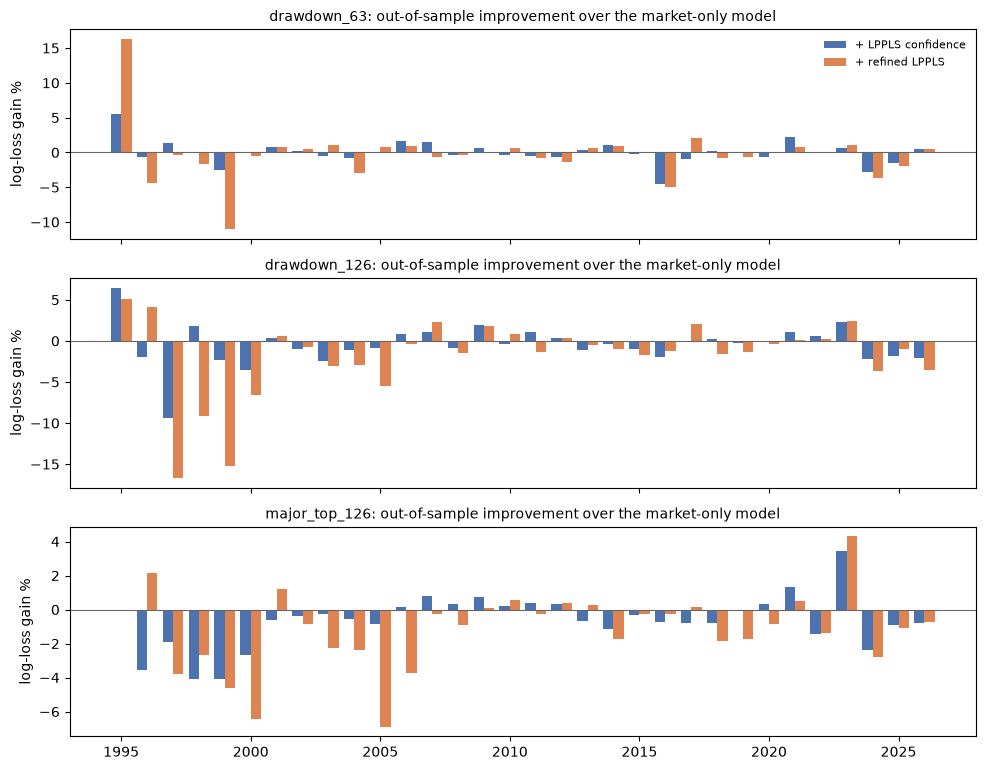

,label,year,n,events,ll_momentum,ap_momentum,ll_market,ap_market,ll_market+lppls,ap_market+lppls,ll_market+refined,ap_market+refined
0,drawdown_63,1995,175,3,0.223,0.020,0.222,0.023,0.210,0.025,0.186,0.030
1,drawdown_63,1996,179,24,0.384,0.303,0.362,0.271,0.364,0.284,0.378,0.295
2,drawdown_63,1997,175,55,0.702,0.515,0.711,0.495,0.701,0.467,0.713,0.471
3,drawdown_63,1998,186,45,0.574,0.418,0.557,0.408,0.557,0.425,0.567,0.422
4,drawdown_63,1999,198,9,0.263,0.179,0.254,0.349,0.260,0.388,0.282,0.378
...,...,...,...,...,...,...,...,...,...,...,...,...
90,major_top_126,2022,410,4,0.061,0.051,0.051,0.189,0.052,0.123,0.052,0.125
91,major_top_126,2023,409,0,0.104,NaN,0.087,NaN,0.084,NaN,0.083,NaN
92,major_top_126,2024,410,50,0.342,0.185,0.339,0.186,0.347,0.168,0.348,0.169
93,major_top_126,2025,362,45,0.414,0.136,0.415,0.159,0.418,0.151,0.419,0.153


In [5]:
display(Image(str(report_dir / "per_year_gain.png")))
T["per_year"].round(3)

## 4 · Calibration

Predicted probability against the realised event rate (deciles of the out-of-sample predictions).
Points on the diagonal are well calibrated.

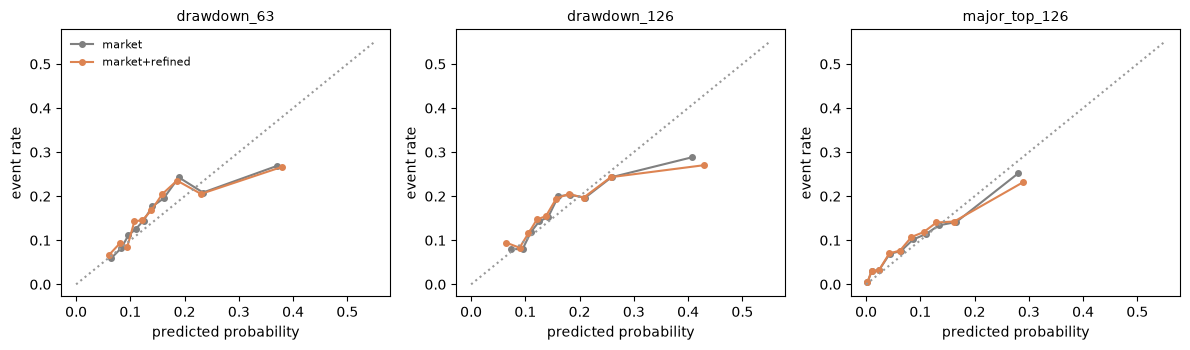

In [6]:
display(Image(str(report_dir / "calibration.png")))

## 5 · Each LPPLS signal on its own

AP, lift over the base rate and the circular time-shift placebo p-value (1,000 shifts). These
are descriptive: no model is fitted.

In [7]:
T["standalone"].pivot_table(index="signal", columns="label", values=["lift", "p_placebo"]).round(3)

lift                              p_placebo                          
label        drawdown_126 drawdown_63 major_top_126 drawdown_126 drawdown_63 major_top_126
signal                                                                                    
conf                1.142       1.133         1.484        0.001       0.002         0.001
conf_agree          1.039       1.072         1.152        0.006       0.001         0.001
conf_cluster        1.138       1.127         1.451        0.001       0.001         0.001
conf_resid          1.140       1.130         1.493        0.001       0.002         0.001
conf_short          1.019       1.046         1.167        0.091       0.004         0.001
lagr_pos            1.038       1.027         1.084        0.001       0.002         0.001
momentum            1.186       1.229         2.241        0.005       0.001         0.001
tc_proximity        1.032       1.041         1.410        0.095       0.047         0.001

## 6 · Coefficients of the largest model (full sample, standardised)

Descriptive only. The coefficients are partial effects given all the other columns, and
correlated signals share their effect.

In [8]:
T["coefficients"].pivot_table(index="term", columns="label", values="coef_per_sd", sort=False).round(3)

label,drawdown_63,drawdown_126,major_top_126
term,,,
intercept,-1.757,-1.679,-2.791
mom_21,-0.013,0.034,0.025
mom_126,0.153,0.022,0.678
mom_252,0.411,0.574,0.331
vol_ratio,0.250,0.271,0.243
drawdown_252,-0.495,-0.406,0.820
conf,-0.239,-0.146,-0.588
conf_short,0.098,0.053,0.057
conf_agree,-0.036,-0.044,-0.078


## 7 · Inside strong rallies

The event rate in the top momentum quintile, split by whether each LPPLS signal fires.

In [9]:
F = T["features"]
lab = [c for c in ("drawdown_63", "drawdown_126", "major_top_126") if c in F]
F = F.dropna(subset=["mom_126"])
hot = F[F["mom_126"] >= F["mom_126"].quantile(0.8)]
rows = []
for sig, thr in [("conf", 0.3), ("conf_short", 0.3), ("conf_agree", 0.3), ("conf_cluster", 0.2),
                 ("conf_resid", 0.2), ("lagr_pos", 0.5)]:
    if hot[sig].notna().any():
        on = hot[sig].fillna(0) >= thr
        rows.append({"signal": f"{sig} >= {thr}", "dates on": int(on.sum()),
                     **{f"{l}: on": hot.loc[on, l].mean() for l in lab},
                     **{f"{l}: off": hot.loc[~on, l].mean() for l in lab}})
pd.DataFrame(rows).set_index("signal").round(3)

,dates on,drawdown_63: on,drawdown_126: on,major_top_126: on,drawdown_63: off,drawdown_126: off,major_top_126: off
signal,,,,,,,
conf >= 0.3,176,0.335,0.418,0.307,0.193,0.195,0.191
conf_short >= 0.3,93,0.312,0.247,0.270,0.200,0.211,0.196
conf_agree >= 0.3,47,0.426,0.289,0.238,0.200,0.211,0.198
conf_cluster >= 0.2,170,0.329,0.378,0.273,0.194,0.199,0.193
conf_resid >= 0.2,299,0.311,0.359,0.274,0.188,0.190,0.188
lagr_pos >= 0.5,183,0.315,0.354,0.244,0.195,0.200,0.195
